In [8]:
# Generate attributions using integrated gradients from Captum AI

# I used DRG pipeline from https://github.com/sasselab/DRG/blob/main/examples/DRGpipeline.ipynb

# Load model and look at attributions

import os
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
import glob
import h5py

import anndata as ad
import grelu
import grelu.lightning
import grelu.data.dataset

# plotting helpers
import matplotlib.pyplot as plt
from drg_tools.plotlib import plot_attribution_maps

from captum.attr import IntegratedGradients


In [9]:
experiment_dir = "final_atac_model_2"
regions_bed = "most_significant_regions/sig_regions_zldrnai_1to15_atac-orer_1to15_atac.bed" # CHANGE
#"t-test_mutant_gd7_vs_orer_1to15_PRIORq_Q_SIGNIFICANT.bed"
#"final_t_test_results_qnorm_q005/t-ATAC_UNION_q_significant_regions.bed" 

genome = "dm6"
seq_len = 200
batch_size = 8
num_workers = 4
device = "cuda" if torch.cuda.is_available() else "cpu"

# Which tasks to explain
task_A_name = "zldrnai_1to15_atac" # CHANGE
task_B_name = "orer_1to15_atac" # CHANGE

# IG hyperparameters / baseline
ig_steps = 256              # can be 64-128
baseline_kind = "uniform"   # "zeros" or "uniform" (0.25 per channel)

# Output
output_dir = "attributions_ig_atac" # CHANGE
os.makedirs(output_dir, exist_ok = True)

In [10]:
# Helper functions
def load_model_from_ckpt(experiment_dlr: str):
    try:
        ckpt = glob.glob(f"{experiment_dlr}/**/*.ckpt", recursive=True)[0]
    except IndexError:
        raise FileNotFoundError(f"No checkpoint found in {experiment_dir}")
    # 1) Force CPU when reading the checkpoint (prevents CUDA tensors from allocating GPU RAM)
    model = grelu.lightning.LightningModel.load_from_checkpoint(ckpt, map_location="cpu")
    model.eval()
    return model
    
def build_ad_for_regions(regions_df: pd.DataFrame):
    df = regions_df.copy()
    # normalize
    df["chrom"] = df["chrom"].astype(str).str.replace("^chr", "", regex=True).radd("chr")
    df["start"] = df["start"].astype(int)
    df["end"]   = df["end"].astype(int)
    
    df["region_id"] = df["chrom"] + ":" + df["start"].astype(str) + "-" + df["end"].astype(str)
    var = df.set_index("region_id")
    obs = pd.DataFrame(index=["dummy"])
    X   = np.zeros((1, len(var)), dtype=np.float32)
    adata = ad.AnnData(X=X, obs=obs, var=var)
    return adata, var.index.tolist()   # region_ids = ['chr2L:12345-14345', ...]


def extract_sequences_from_batch(batch):
    """Return sequence tensor [B, 4, L] from common batch formats."""
    if isinstance(batch, dict):
        x = batch.get("sequence", None)
        if x is None:
            for v in batch.values():
                if torch.is_tensor(v) and v.ndim == 3 and v.shape[1] == 4:    
                    """Check if v is a tensor,
                    Check if it has 3 dimensions ([B, 4, L])
	        	    Check if the second dimension is 4 (nucleotide channels)
                    As soon as such a tensor is found, assign it to x."""
                    x = v; break
        if x is None:
            raise RuntimeError("Could not find 'sequence' tensor in dict batch.")
        return x
    if isinstance(batch, (list, tuple)):
        x = batch[0]
        if not torch.is_tensor(x):
            raise RuntimeError("First element of batch is not a tensor; adjust extractor.")
        return x
    if torch.is_tensor(batch):
        return batch
    raise RuntimeError("Unknown batch structure; customize extract_sequences_from_batch().")


def save_h5(path, attrs_array, region_ids, task_name, seq_len, meta: dict, sequences=None):
    with h5py.File(path, "w") as h:
        h.create_dataset("attributions", data=attrs_array, compression="gzip", compression_opts=6)
        ascii_ids = np.asarray(region_ids, dtype="S")
        h.create_dataset("region_ids", data=ascii_ids)
        if sequences is not None:
            h.create_dataset("sequences", data=sequences, compression="gzip", compression_opts=6)
        h.attrs["task_name"] = task_name
        h.attrs["seq_len"] = int(seq_len)
        for k, v in meta.items():
            h.attrs[k] = v


def extract_task_names(raw):
    """ Robustly extract a Series[str] from various checkpoint formats.
    --> no matter how raw is stored in the checkpoint (list, tuple, maybe dict later), normalize it into a Pandas Series of strings.
	-->	A Series is useful because it has an index and string dtype, easy for downstream alignment.
    """
    if isinstance(raw, (list, tuple)):                              #Sometimes checkpoints store task names like: ["task1", "task2", "task3"] or ("task1", "task2")
        if len(raw) == 0: return pd.Series([], dtype="string")      # If it’s an empty list/tuple, just return an empty Series of strings.
        
        """
        Peek at the first element to infer the type.
		--> If it’s a string, then the whole list/tuple is probably a list of task names.
		--> Convert it to a Pandas Series, explicitly with dtype="string".
        """
        first = raw[0]
        if isinstance(first, str): return pd.Series(list(raw), dtype="string")
        
        """
        If raw is a list/tuple whose elements are dicts, checkpoints often store task info as objects:
        raw = [
            {"name": "orer_1to15_atac", "other": ...},
            {"name": "gd7_1to15_atac",  "other": ...},
        ]
        This looks for a likely name field among common keys: name, task_name, task, label, id, title.
        """
        if isinstance(first, dict):
            cand = ["name", "task_name", "task", "label", "id", "title"]
            key = next((k for k in cand if k in first), None)
            # If found, build a Series by extracting d[key] from each dict (casting to str, filling "" if missing).
            if key: return pd.Series([str(d.get(key, "")) for d in raw], dtype="string")
            # If no key matches, fall back to stringifying the dicts:
            return pd.Series([str(d) for d in raw], dtype="string")
    
    # If it is already a Pandas series:
    if isinstance(raw, pd.Series): return raw.astype("string")

    # If raw isn’t a list of strings/dicts or a Series, try turning it into a DataFrame.
    # Many structures (list of dicts, dict-of-lists, structured arrays) convert nicely to a DataFrame.
    try:
        df = pd.DataFrame(raw)
        # After conversion:
		# Prefer a well-known column (name, task_name, etc.). If found, return that column as string.
		# Otherwise, just take the first column (df.iloc[:, 0]) as a reasonable default.
        for col in ["name", "task_name", "task", "label", "id", "title"]:
            if col in df.columns: return df[col].astype("string")
        return df.iloc[:,0].astype("string")
    
    
    # Final fallback: If DataFrame conversion fails (e.g., raw is a weird object or completely incompatible), don’t crash.
    # Return a 1-element Series with str(raw) so the caller gets something.
    except Exception:
        return pd.Series([str(raw)], dtype="string")

In [11]:
def compute_ig_for_task(model, loader, task_idx, ig_steps, baseline_kind, device):

    ig = IntegratedGradients(model, multiply_by_inputs=False)

    N = len(loader.dataset)
    L = getattr(loader.dataset, "seq_len", None) or seq_len

    tmp_attrs_path = os.path.join(output_dir, f"._tmp_attrs_task{task_idx}.mmap")
    all_attrs = np.memmap(tmp_attrs_path, dtype=np.float32, mode="w+", shape=(N, 4, L))

    pos = 0
    for batch in loader:
        x = extract_sequences_from_batch(batch).to(device).float()
        x.requires_grad_(True)

        if baseline_kind == "zeros":
            baseline = torch.zeros_like(x)
        elif baseline_kind == "uniform":
            baseline = torch.full_like(x, 0.25)
        else:
            raise ValueError("baseline_kind must be 'zeros' or 'uniform'.")

        attrs = ig.attribute(
            inputs=x,
            baselines=baseline,
            target=task_idx,                 
            n_steps=ig_steps,
            internal_batch_size=batch_size,
            return_convergence_delta=False
        )
        # center across channels
        attrs = attrs - attrs.mean(dim=1, keepdim=True)

        B = x.shape[0]
        all_attrs[pos:pos+B] = attrs.detach().cpu().numpy()
        pos += B

        del attrs, x, baseline
        if device.startswith("cuda"):
            torch.cuda.empty_cache()

    # flush and close the memmap
    del all_attrs

    # Reopen read-only and copy to plain ndarray, then clean temp
    attrs_array = np.memmap(tmp_attrs_path, dtype=np.float32, mode="r", shape=(N, 4, L))
    attrs_copy = np.array(attrs_array, copy=True)
    del attrs_array
    os.remove(tmp_attrs_path)
    return attrs_copy

    
def project_to_observed_base(attrs, onehot):
    """
    attrs: (N 4, L) channel-centered IG
    onehot: (N, 4, L) one-hot sequence
    returns per-position score (N, L) and projected channels (N, 4, L)
    """

    ig_proj = attrs * onehot
    per_pos = ig_proj.sum(axis=1)  # (N, L)
    return per_pos, ig_proj


In [12]:
# Main

def main():
    print("Loading model...")
    model = load_model_from_ckpt(experiment_dir).eval()
        # 2) Move to GPU only right before needed
    model = model.to(device)

    raw_tasks = model.data_params.get("tasks")
    all_task_names = extract_task_names(raw_tasks)
    atac_mask = all_task_names.str.contains("atac", case=False, na=False)
    atac_tasks = list(all_task_names[atac_mask])                # list[str]

    print(f"Found {len(all_task_names)} total tasks.")
    print(f"Found {len(atac_tasks)} ATAC tasks: {atac_tasks}")

    if task_A_name not in atac_tasks or task_B_name not in atac_tasks:
        raise ValueError(f"Tasks '{task_A_name}' or '{task_B_name}' not in trained ATAC tasks: {atac_tasks}")
    task_A_idx = atac_tasks.index(task_A_name)
    task_B_idx = atac_tasks.index(task_B_name)
    print(f"Task A: {task_A_name}: idx = {task_A_idx}")
    print(f"Task B: {task_B_name}: idx = {task_B_idx}")

    print("Loading regions...")
    regions_df = pd.read_csv(regions_bed, sep="\t", header=None, names=["chrom", "start", "end"])
    adata, region_ids = build_ad_for_regions(regions_df)
    dataset = grelu.data.dataset.AnnDataSeqDataset(
        adata, genome=genome, seq_len=seq_len, rc=False, max_seq_shift=0
    )

    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)  #pin_memory=True: speeds up GPU transfer.


    print("Collecting one-hot sequences...")
    N = len(dataset)
    L = seq_len

    tmp_ohe_path = os.path.join(output_dir, f"._tmp_ohe_task.mmap")
    all_ohe = np.memmap(tmp_ohe_path, dtype=np.float32, mode="w+", shape=(N, 4, L))
    pos = 0
    
    for batch in loader:
        x = extract_sequences_from_batch(batch)
        B = x.shape[0]
        all_ohe[pos:pos+B] = x.detach().cpu().numpy()
        pos += B
    del all_ohe
    ohe_array = np.memmap(tmp_ohe_path, dtype=np.float32, mode="r", shape=(N, 4, L)) 
    ohe_copy = np.array(ohe_array, copy=True)    # with shape (N, 4, L) → all one-hot sequences



    os.remove(tmp_ohe_path)

    # Compute IG for both tasks
    print("Computing IG (Task A)...")
    A_attrs = compute_ig_for_task(model, DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True),
                                    task_A_idx, ig_steps, baseline_kind, device)
    
    print("Computing IG (Task B)...")
    B_attrs = compute_ig_for_task(model, DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True),
                                    task_B_idx, ig_steps, baseline_kind, device)


    meta = {
        "method": "IntegratedGradients",
        "ig_n_steps": int(ig_steps),
        "baseline": baseline_kind,
        "centered": True,      
    }

    outA_h5 = os.path.join(output_dir, f"ig_attributions_{task_A_name}_only_sig.h5")
    outB_h5 = os.path.join(output_dir, f"ig_attributions_{task_B_name}_only_sig.h5")
    save_h5(outA_h5, A_attrs, region_ids, task_A_name, L, meta, sequences=ohe_copy)
    save_h5(outB_h5, B_attrs, region_ids, task_B_name, L, meta, sequences=ohe_copy)


    # Save tf-MoDISco-lite inputs (.npz)
    np.savez_compressed(os.path.join(output_dir, f"ohe_{task_A_name}.npz"), ohe_copy.astype(np.float32))
    np.savez_compressed(os.path.join(output_dir, f"ohe_{task_B_name}.npz"), ohe_copy.astype(np.float32))
    np.savez_compressed(os.path.join(output_dir, f"shap_{task_A_name}.npz"), A_attrs.astype(np.float32))
    np.savez_compressed(os.path.join(output_dir, f"shap_{task_B_name}.npz"), B_attrs.astype(np.float32))
    print(f"Saved H5/NPZ for {task_A_name} and {task_B_name}.")


    """
    Writes two compressed .npz files for tf-MoDISco-lite
        •	ohe_<task>.npz  → the sequences (one-hot)     (N, 4, L)
        •	shap_<task>.npz → the attributions (IG/SHAP)  (N, 4, L)
    """


if __name__ == "__main__":
    main()


Loading model...
Found 14 total tasks.
Found 14 ATAC tasks: ['zldrnai_15to2_atac', 'zldrnai_1to15_atac', 'gd7_1to15_atac', 'gd7_15to2_atac', 'orer_2to25_atac', 'zldrnai_25to3_atac', 'gd7_2to25_atac', 'orer_1to15_atac', 'cic6_2to25_atac', 'orer_25to3_atac', 'zldrnai_2to25_atac', 'cic6_25to3_atac', 'orer_15to2_atac', 'gd7_25to3_atac']
Task A: zldrnai_1to15_atac: idx = 1
Task B: orer_1to15_atac: idx = 7
Loading regions...
Computing IG (Task A)...
Computing IG (Task B)...
Saved H5/NPZ for zldrnai_1to15_atac and orer_1to15_atac.


In [13]:
"""
I ran:
modisco motifs \
  -s attributions_ig_final_atac_model_only_sig/ohe_orer_1to15_atac.npz \
  -a attributions_ig_final_atac_model_only_sig/shap_orer_1to15_atac.npz \
  -w 2000 \
  -n 2000 \
  -o attributions_ig_final_atac_model_only_sig/modisco_results.h5

modisco report \
  -i attributions_ig_final_atac_model_only_sig/modisco_results.h5 \
  -o attributions_ig_final_atac_model_only_sig/report \
  -s attributions_ig_final_atac_model_only_sig/report \
  -m attributions_ig_final_atac_model_only_sig/jaspar_insects_2024.meme

"""

'\nI ran:\nmodisco motifs   -s attributions_ig_final_atac_model_only_sig/ohe_orer_1to15_atac.npz   -a attributions_ig_final_atac_model_only_sig/shap_orer_1to15_atac.npz   -w 2000   -n 2000   -o attributions_ig_final_atac_model_only_sig/modisco_results.h5\n\nmodisco report   -i attributions_ig_final_atac_model_only_sig/modisco_results.h5   -o attributions_ig_final_atac_model_only_sig/report   -s attributions_ig_final_atac_model_only_sig/report   -m attributions_ig_final_atac_model_only_sig/jaspar_insects_2024.meme\n\n'

BED regions: 8
Using N=8 regions, length=200 bp, channels=4 (A and B).


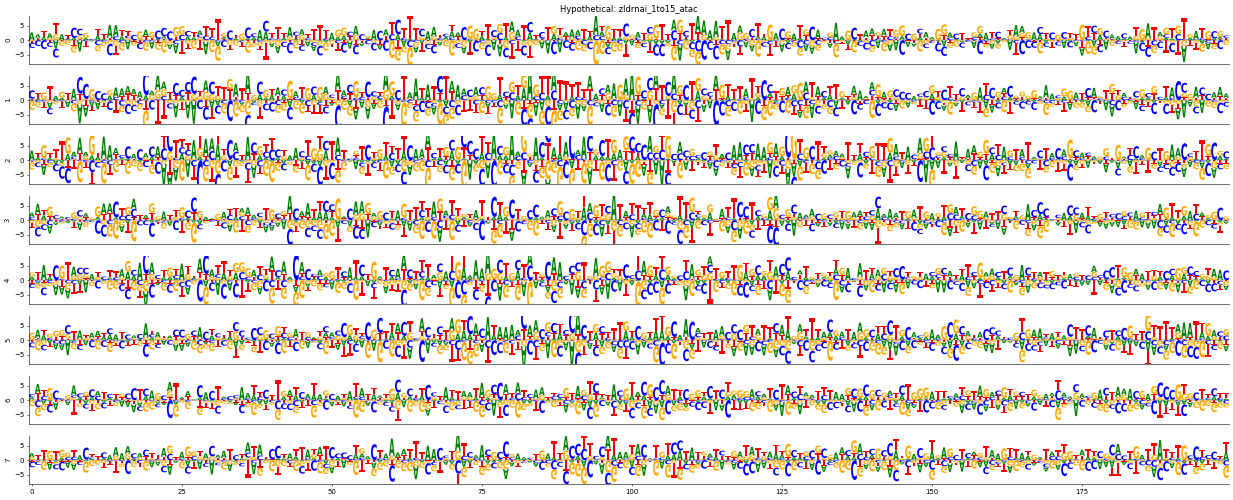

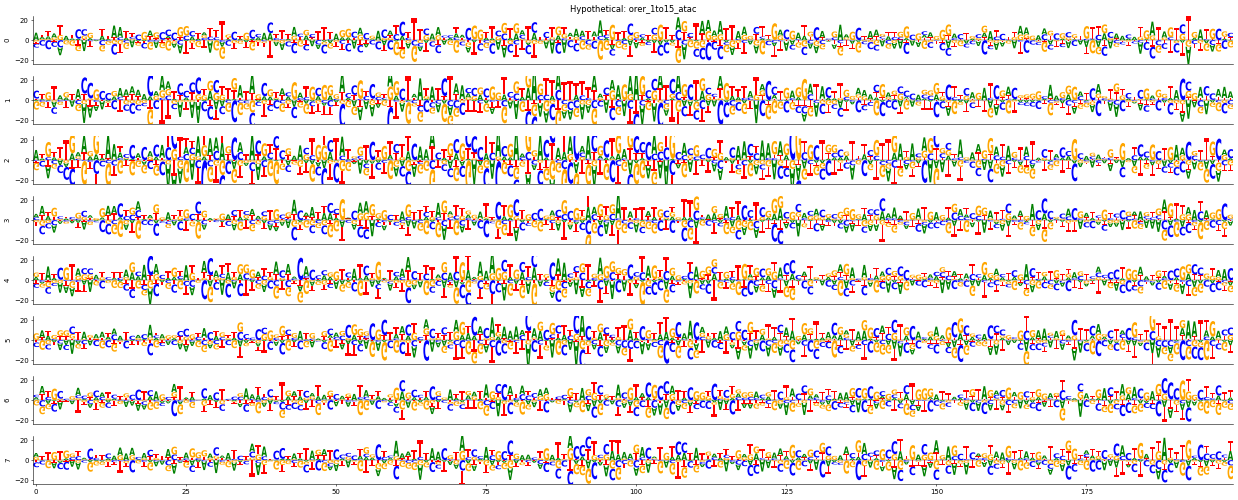

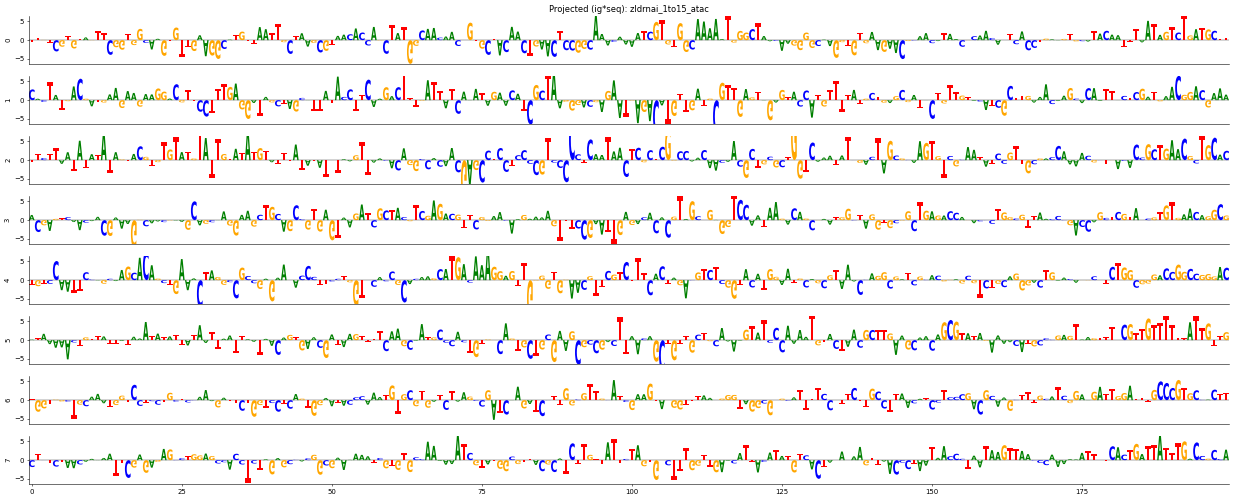

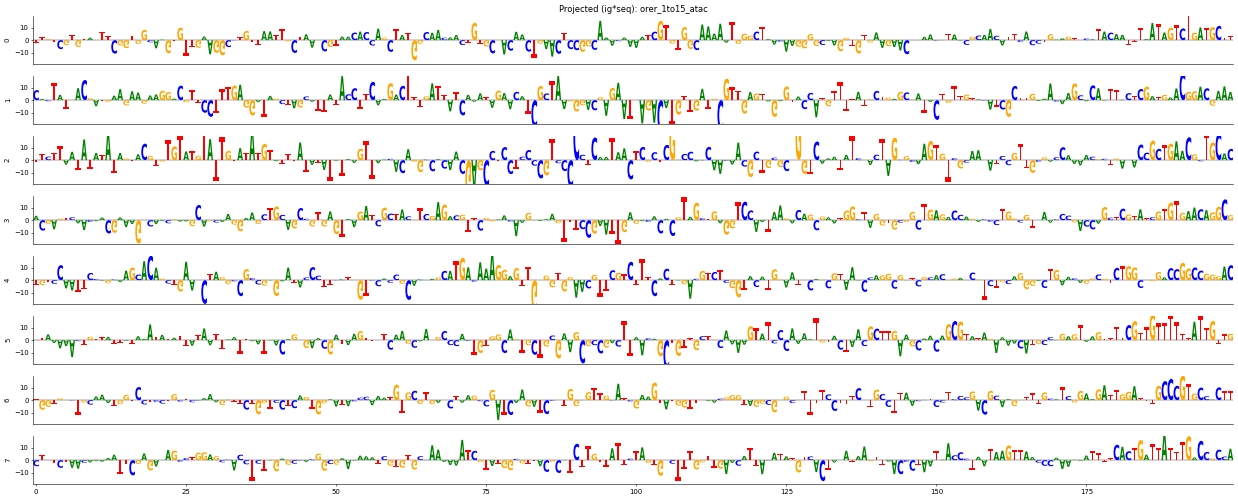

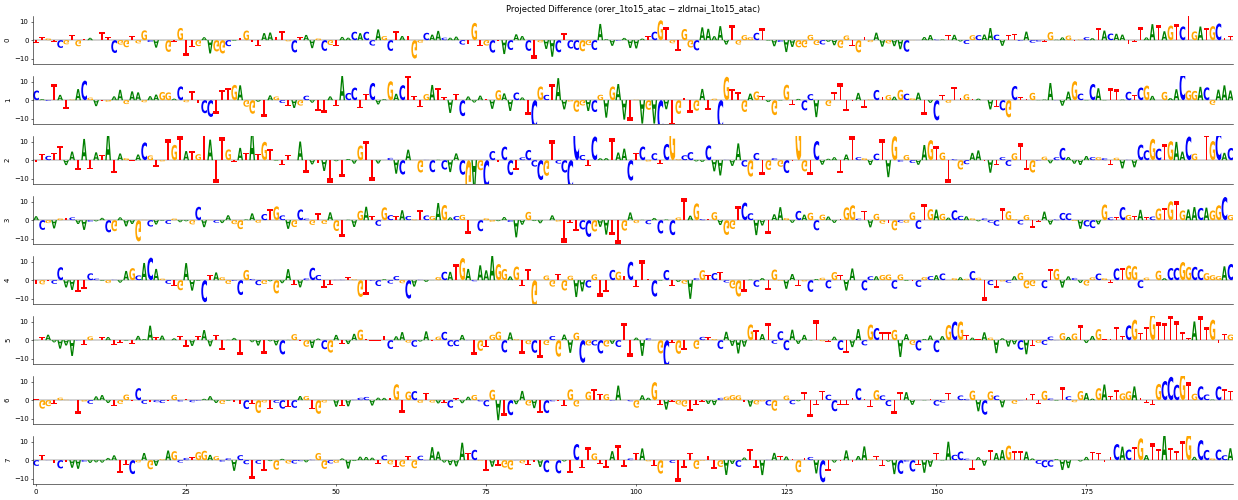

Saved:
  - attribution_maps_orer_vs_zldrnai_1to15_zldrnai_1to15_atac_hypothetical.png
  - attribution_maps_orer_vs_zldrnai_1to15_orer_1to15_atac_hypothetical.png
  - attribution_maps_orer_vs_zldrnai_1to15_zldrnai_1to15_atac_projected.png
  - attribution_maps_orer_vs_zldrnai_1to15_orer_1to15_atac_projected.png
  - attribution_maps_orer_vs_zldrnai_1to15_orer_1to15_atac-minus-zldrnai_1to15_atac_projected.png


In [ ]:
import h5py, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import re


taskA_name = "zldrnai_1to15_atac" # CHANGE
taskB_name = "orer_1to15_atac"

h5_taskA = f"attributions_ig_atac/ig_attributions_{taskA_name}_only_sig.h5"
h5_taskB = f"attributions_ig_atac/ig_attributions_{taskB_name}_only_sig.h5"

bed_path = "most_significant_regions/sig_regions_zldrnai_1to15_atac-orer_1to15_atac.bed"   # CHANGE
save_prefix = "attribution_maps_orer_vs_zldrnai_1to15"  # CHANGE



try:
    from drg_tools.plotlib import plot_attribution_maps
except Exception:
    plot_attribution_maps = None

def read_bed(path):
    """Read BED with >= 3 cols -> chrom, start, end; keep any extra as name if present."""
    cols = ["chrom", "start", "end", "name", "score", "strand"]
    df = pd.read_csv(path, sep="\t", header=None, comment="#")
    n = df.shape[1]
    df.columns = cols[:n]
    
    region_id = df["chrom"].astype(str) + ":" + df["start"].astype(str) + "-" + df["end"].astype(str)
    df["region_id"] = region_id
    return df[["chrom","start","end","region_id"]]

def _first_existing_key(h5, candidates):
    """Return the first key that exists in the file from a list of candidates."""
    for k in candidates:
        if k in h5:
            return k
    
    for g in h5.keys():
        if isinstance(h5[g], h5py.Group):
            for k in candidates:
                if k in h5[g]:
                    return f"{g}/{k}"
    return None

def load_ig_h5(path):
    """
    Try to load:
      - attributions: (N, L, 4) or (N, 1, 4, L) or (N, 4, L)
      - region_ids:   (N,) array of strings
      - sequences:    (N, L, 4) one-hot if present (optional)
    Returns dict with 'attr', 'region_ids', 'seq' (or None)
    """
    with h5py.File(path, "r") as h5:
        # region IDs
        region_key = _first_existing_key(h5, ["region_ids", "regions", "ids", "names"])
        if region_key is None:
            raise ValueError(f"No region_id key found in {path}. Keys: {list(h5.keys())}")
        # read strings 
        rid = h5[region_key][:]
        if hasattr(rid, "dtype") and rid.dtype.kind in ("S", "O"):
            region_ids = np.array([r.decode() if isinstance(r, (bytes, bytearray)) else str(r) for r in rid])
        else:
            region_ids = rid.astype(str)

        # attributions
        attr_key = _first_existing_key(h5, ["attributions", "ig", "attr", "IG"])
        if attr_key is None:
            
            big_arrays = []
            def walk(g, prefix=""):
                for k, v in g.items():
                    if isinstance(v, h5py.Dataset) and v.ndim in (3,4) and v.shape[0] == len(region_ids):
                        big_arrays.append(prefix+k)
                    elif isinstance(v, h5py.Group):
                        walk(v, prefix+k+"/")
            walk(h5, "")
            if not big_arrays:
                raise ValueError(f"No attribution array found in {path}. Keys: {list(h5.keys())}")
            attr_key = big_arrays[0]
        attr = h5[attr_key][:]

        # optional sequences
        seq_key = _first_existing_key(h5, ["sequences", "one_hot", "X", "seq"])
        seq = h5[seq_key][:] if seq_key else None

    # Normalize attribution shape to (N, L, 4)
    if attr.ndim == 4:
        # common shapes: (N, 1, 4, L) or (N, C, L, 4) or (N, 4, L, 1) 
        if attr.shape[1] in (1,4) and attr.shape[2] in (4,) and attr.shape[3] >= 50:
            # (N, 1|4, 4, L)
            if attr.shape[1] == 1:
                attr = attr[:,0]  # (N, 4, L)
            # (N, 4, L)
            attr = np.transpose(attr, (0, 2, 1))  # -> (N, L, 4)
        elif attr.shape[-1] == 4:
            # (N, L, C, 4) or (N, ?, L, 4) — assume C==1 or already L in position -2
            if attr.shape[-2] >= 50:
                attr = attr[:, :, :, :]  # keep
                # If shape is (N, 1, L, 4) squeeze the middle
                if attr.shape[1] == 1:
                    attr = attr[:, 1-1]   # (N, L, 4)
            else:
                raise ValueError(f"Unsupported 4D attr shape {attr.shape}, please adjust.")
        else:
    
            axes = list(range(4))
            ch_ax = [i for i,s in enumerate(attr.shape) if s==4]
            len_ax = [i for i,s in enumerate(attr.shape) if s>=50 and i!=0]
            if ch_ax and len_ax:
                attr = np.moveaxis(attr, ch_ax[0], -1)
                attr = np.moveaxis(attr, len_ax[0] if len_ax[0]!=0 else (len_ax[1] if len_ax[1]!=0 else len_ax[0]), -2)
                if attr.shape[1] == 1: attr = attr[:,0]
            else:
                raise ValueError(f"Cannot infer axes from {attr.shape}")
    elif attr.ndim == 3:
        # (N, 4, L) or (N, L, 4)
        if attr.shape[1] == 4 and attr.shape[2] >= 50:
            attr = np.transpose(attr, (0, 2, 1))  # (N, L, 4)
        elif attr.shape[2] == 4:
            pass  # already (N, L, 4)
        else:
            raise ValueError(f"3D attr with unknown layout {attr.shape}")

    # Normalize sequences shape to (N, L, 4) if present
    if seq is not None:
        if seq.ndim == 3:
            if seq.shape[1] == 4 and seq.shape[2] >= 50:
                seq = np.transpose(seq, (0, 2, 1))
            elif seq.shape[2] == 4:
                pass
            else:
                seq = None  
        else:
            seq = None

    return {"attr": attr, "region_ids": np.array(region_ids), "seq": seq}

def _normalize_chrom(ch):
    ch = str(ch)
    ch = ch.replace("chr", "")
    return "chr" + ch  # normalize with chr prefix

def _parse_region_id(r):
    if isinstance(r, (bytes, bytearray)):
        r = r.decode()
    s = str(r).strip()

    m = re.match(r"^(chr)?([A-Za-z0-9_.]+):([\d,]+)-([\d,]+)$", s)
    if m:
        chrom = "chr" + m.group(2)
        start = int(m.group(3).replace(",", ""))
        end   = int(m.group(4).replace(",", ""))
        return (_normalize_chrom(chrom), min(start,end), max(start,end))

    m = re.match(r"^(chr)?([A-Za-z0-9_.]+)[_\s]+([\d,]+)[_\s]+([\d,]+)$", s)
    if m:
        chrom = "chr" + m.group(2)
        start = int(m.group(3).replace(",", ""))
        end   = int(m.group(4).replace(",", ""))
        return (_normalize_chrom(chrom), min(start,end), max(start,end))

    toks = re.split(r"[ :\t|]+", s)
    if len(toks) >= 3 and toks[1].replace(",","").isdigit() and toks[2].replace(",","").isdigit():
        chrom = toks[0]
        start = int(toks[1].replace(",", ""))
        end   = int(toks[2].replace(",", ""))
        return (_normalize_chrom(chrom), min(start,end), max(start,end))

    return None

def _h5_regions_to_df(region_ids):
    rows = []
    for i, rid in enumerate(region_ids):
        parsed = _parse_region_id(rid)
        if parsed is None:
            rows.append((i, None, None, None, str(rid)))
        else:
            chrom, start, end = parsed
            rows.append((i, chrom, start, end, str(rid)))
    return pd.DataFrame(rows, columns=["h5_idx", "chrom", "start", "end", "raw"])

def align_bed_to_h5_by_overlap(bed_df, h5_region_ids):
    h5_df = _h5_regions_to_df(h5_region_ids).dropna(subset=["chrom"])
    bed = bed_df.copy()
    bed["chrom"] = bed["chrom"].apply(_normalize_chrom)

    matched_idx, missing = [], []
    for _, row in bed.iterrows():
        chrom, s, e = row["chrom"], int(row["start"]), int(row["end"])
        cand = h5_df[h5_df["chrom"] == chrom]
        if cand.empty:
            missing.append(f"{chrom}:{s}-{e} (no chrom match)")
            continue

        left  = np.maximum(cand["start"].values, s)
        right = np.minimum(cand["end"].values, e)
        overlap = np.maximum(0, right - left)

        if (overlap > 0).any():
            best = cand.iloc[int(np.argmax(overlap))]
            matched_idx.append(best["h5_idx"])
        else:
            bed_center = (s + e) / 2.0
            cand_center = (cand["start"] + cand["end"]) / 2.0
            dist = np.abs(cand_center.values - bed_center)
            best = cand.iloc[int(np.argmin(dist))]
            matched_idx.append(best["h5_idx"])

    if len(matched_idx) == 0:
        raise ValueError("Could not match any BED regions to H5 by overlap or proximity.")

    if missing:
        print(f"[WARN] {len(missing)} BED regions had no same-chrom candidates. Example: {missing[:2]}")

    return np.array(matched_idx, dtype=int)


# Load all
bed_df = read_bed(bed_path)
print(f"BED regions: {len(bed_df)}")

A = load_ig_h5(h5_taskA)
B = load_ig_h5(h5_taskB)

idxA = align_bed_to_h5_by_overlap(bed_df, A["region_ids"])
idxB = align_bed_to_h5_by_overlap(bed_df, B["region_ids"])


if len(idxA) != len(idxB):
    chromsA = set(_h5_regions_to_df(A["region_ids"])["chrom"].dropna())
    chromsB = set(_h5_regions_to_df(B["region_ids"])["chrom"].dropna())
    bed_df = bed_df[bed_df["chrom"].apply(lambda c: _normalize_chrom(c) in (chromsA & chromsB))].reset_index(drop=True)
    idxA = align_bed_to_h5_by_overlap(bed_df, A["region_ids"])
    idxB = align_bed_to_h5_by_overlap(bed_df, B["region_ids"])

attrA = A["attr"][idxA]   # (N, L, 4)
attrB = B["attr"][idxB]   # (N, L, 4)
seqA  = A["seq"][idxA] if A["seq"] is not None else None  
seqB  = B["seq"][idxB] if B["seq"] is not None else None

if attrA.shape != attrB.shape:
    raise ValueError(f"Shape mismatch A {attrA.shape} vs B {attrB.shape} after alignment.")
N, L, C = attrA.shape
print(f"Using N={N} regions, length={L} bp, channels={C} (A and B).")

# Difference: B - A
diff_attr = attrB - attrA

# Nice symmetric color limits for difference (percentile-based)
def robust_vlim(x, q=99.5):
    m = np.nanpercentile(np.abs(x), q)
    return (-m, m)

vlim_A   = robust_vlim(attrA)
vlim_B   = robust_vlim(attrB)
vlim_d   = robust_vlim(diff_attr)

# Plotting
# If you have drg_tools.plotlib.plot_attribution_maps, we use it for the same style.
def plot_maps(arr, seq=None, title="", vlim=None, outfile=None):
    if plot_attribution_maps is None:
        # Minimal fallback plot: one row per region, letter-summed attribution heatmap
        # (A+C+G+T per position), just so you see something similar.
        summed = arr.sum(axis=2)  # (N, L)
        fig, axes = plt.subplots(nrows=summed.shape[0], ncols=1, figsize=(10, 0.6*summed.shape[0]), sharex=True)
        if summed.shape[0] == 1:
            axes = [axes]
        for i, ax in enumerate(axes):
            im = ax.imshow(summed[i:i+1, :], aspect='auto', vmin=(vlim[0] if vlim else None), vmax=(vlim[1] if vlim else None))
            ax.set_ylabel(f"#{i+1}", rotation=0, labelpad=10, va="center")
            ax.set_yticks([])
        axes[-1].set_xlabel("Position (bp)")
        fig.suptitle(title)
        plt.tight_layout()
        if outfile: fig.savefig(outfile, dpi=200)
        return fig
    else:
        # Use drg_tools styling (expects (N, L, 4) and optional seq (N, L, 4))
        fig = plot_attribution_maps(
            arr, 
            seq=seq, motifs=None, experiments=None,
            vlim=vlim, unit=0.15, ratio=10, ylabel=None,
            xtick_range=None, barplot=None, heatmap=False
        )
        if title:
            try:
                fig.axes[0].set_title(title)
            except Exception:
                pass
        if outfile: fig.savefig(outfile, dpi=200, bbox_inches="tight")
        return fig

# Titles list to annotate rows
row_labels = bed_df["region_id"].tolist()

# 1) Hypothetical maps (all 4 bases per position) 
figA_hyp = plot_maps(
    attrA, seq=None,
    title=f"Hypothetical: {taskA_name}",
    vlim=vlim_A,
    outfile=f"{save_prefix}_{taskA_name}_hypothetical.png"
)
figB_hyp = plot_maps(
    attrB, seq=None,
    title=f"Hypothetical: {taskB_name}",
    vlim=vlim_B,
    outfile=f"{save_prefix}_{taskB_name}_hypothetical.png"
)

# 2) Projected maps (ig * seq) — single observed base per position 
saved_paths = [
    f"{save_prefix}_{taskA_name}_hypothetical.png",
    f"{save_prefix}_{taskB_name}_hypothetical.png",
]

if (seqA is not None) and (seqB is not None):
    projA = attrA * seqA
    projB = attrB * seqB

    vlim_Ap = robust_vlim(projA)
    vlim_Bp = robust_vlim(projB)

    figA_proj = plot_maps(
        projA, seq=None,
        title=f"Projected (ig*seq): {taskA_name}",
        vlim=vlim_Ap,
        outfile=f"{save_prefix}_{taskA_name}_projected.png"
    )
    figB_proj = plot_maps(
        projB, seq=None,
        title=f"Projected (ig*seq): {taskB_name}",
        vlim=vlim_Bp,
        outfile=f"{save_prefix}_{taskB_name}_projected.png"
    )
    saved_paths += [
        f"{save_prefix}_{taskA_name}_projected.png",
        f"{save_prefix}_{taskB_name}_projected.png",
    ]

    # 3) Difference on projected maps
    diff_proj = projB - projA
    vlim_dp = robust_vlim(diff_proj)
    figD_proj = plot_maps(
        diff_proj, seq=None,
        title=f"Projected Difference ({taskB_name} − {taskA_name})",
        vlim=vlim_dp,
        outfile=f"{save_prefix}_{taskB_name}-minus-{taskA_name}_projected.png"
    )
    saved_paths.append(f"{save_prefix}_{taskB_name}-minus-{taskA_name}_projected.png")
else:
    print("[WARN] sequences not found in H5 → skipping projected (ig*seq) maps. "
          "Make sure you saved 'sequences' into the H5 when writing attributions.")

plt.show()

print("Saved:")
for p in saved_paths:
    print("  -", p)